# The rollout tool: any trained model on any stimulus programme

A trained model is a simulated fish: give it a stimulus programme and it swims it, bout by bout, in closed loop
(`twin/stim_rollout.py`). The programme can be the one the rig played, any trajectory file in the rig's format, or
one built in code. As in the rig (`CLsemi`), each block is anchored to the fish's own pose at the block onset, so the
same programme lands in a different place for every fish.

Outputs: N simulated fish, their distance to the dots per block, their trajectories, a check against the real fish
(on the rig's programme) and a video of two stimulus windows with the simulated fish next to real ones. Needs the
model's checkpoints (`output/checkpoints/`, from the output zip) and, for the real fish, `data/` (the data zip).
Everything is written to `output/experiments/rollout_tool/`.

<a id="contents"></a>
**Contents**

1. [Model and programme](#params)
2. [A programme of your own](#own)
3. [Warning: bout-indexed](#warning)
4. [The simulated fish](#rollouts)
5. [Distance to the dots, per block](#distance)
6. [Trajectories](#trajectories)
7. [Against the real fish](#check)
8. [Video](#video)

<a id="params"></a>
## Model and programme

- `MODEL`: a model of the thesis by name (`twin/registry.py`; the list is printed below), `SEED` its
  cross-validation seed. Simulated fish k is run by fold model k mod 5 (each fold model never saw three fish).
- `PROGRAM`: `"rig"` (the programme of the experiment, 174 min, 95 blocks), `"ring"` (the example below) or the
  path of a trajectory file in the rig's format.
- `N_FISH`, `ROLL_SEED`: number of simulated fish and their random stream (fish k: `default_rng([ROLL_SEED, k])`).
- `REAL_FISH`: real fish shown next to the simulated ones in the video (rig programme only).

[↑ back to contents](#contents)

In [1]:
import contextlib
import io
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display

from twin import model_figures as MFg
from twin import paths, registry
from twin import rollout_video as RV
from twin import stim_program as SP
from twin import stim_rollout as SR
from twin import tool_reference as TR
from twin.segment_bouts import PX_PER_MM

MODEL, SEED = "F", 0
PROGRAM = "rig"            # "rig", "ring" or a path to a trajectory file
N_FISH, ROLL_SEED = 6, 0
REAL_FISH = (0, 8, 14)
VIDEO_SPEED = 3.0
OUT = paths.EXPERIMENTS / "rollout_tool"

print("models:", " | ".join(sorted({n for n, s in registry.BY_NAME})))
key = registry.BY_NAME[(MODEL, SEED)]
with contextlib.redirect_stdout(io.StringIO()):
    folds, _ = MFg.fold_models(registry.ckpt_dir(key), registry.arm(key))
models = [folds[f] for f in sorted(folds)]
rig, dish, ref = MFg._programme()                  # the rig's programme, the median dish, the real start poses
print(f"{MODEL} seed {SEED}: unit {key}, {len(models)} fold models")
def show(mp4, width=900):
    """Play a video in the notebook (a link to the file, not embedded: open the notebook locally to play it)."""
    try:
        p = Path(os.path.relpath(mp4)).as_posix()
    except ValueError:                                   # another drive
        p = str(mp4)
    display(Video(p, embed=False, width=width, html_attributes="controls loop muted"))

models: D1 | D2 | D3 | D4 | D4, 3 layers | D4, floor 2 px | D4, jump phase | D4, strength 0 | D4, tau 200 | D4, tau 200 + turn size | D4, tau 200, full | D4, tau 200, half | D4, tau 70, full | D4, tau 70, half | D4, turn size | F | F on D4 at strength 0 | F, 3 layers | F, floor 2 px | F, jump phase | F, tau 200 | F, tau 200 + turn size | F, turn size | M1 | M2 | M3 | M4 | M5 | M5+R | M5+T | M6 | M6, 3 layers | M6, floor 2 px | M6, jump phase | M6, turn size | M6-block clock | M6-count | M6-kin0 | M6-kin1 | M6-kin2 | M6-kin4 | M6-kin5 | M6-motion | M6-pos | M6-range | M6-run clock | M6-stim | M6-turn0 | M6-turn1 | M6-turn3 | M6-turn4 | M6-x3 | M6-z


F seed 0: unit 14f, 5 fold models


<a id="own"></a>
## A programme of your own

`SP.write_program(blocks, path)` writes a trajectory file in the rig's format and `SP.build_program` reads it back
through the same reader as the rig's file. Each block is `(duration_s, dots, moving)`: `dots(t)` returns the
positions of up to 8 dots (mm) relative to the fish's pose at the block onset, x to its left and y ahead of it, at the
times `t` (s from the onset); `moving` is what the model is told (the moving flag). Each block is preceded by a 50 s
pause. The example: 4 dots on a circle of radius 15 mm, 25 mm ahead of the fish, turning (moving) and then still.

[↑ back to contents](#contents)

In [2]:
def ring(t, k=4, r=15.0, ahead=25.0, turn=0.3):
    """k dots on a circle of radius r (mm) centred `ahead` mm in front of the fish, turning at `turn` rad/s."""
    a = 2 * np.pi * np.arange(k) / k + turn * np.asarray(t)[:, None]
    return r * np.cos(a), ahead + r * np.sin(a)


blocks = [(60, ring, True), (60, lambda t: ring(t, turn=0.0), False)] * 3
if PROGRAM == "rig":
    program = rig
elif PROGRAM == "ring":
    program = SP.build_program(blocks, OUT / "ring_trajectory.csv")
else:
    program = SP.load_program(PROGRAM)
print(program.summary())
program.block_table().head(6)

2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz: 315000 frames (175.0 min @ 30 fps), 8 dot slots
  191 blocks -> 95 stimulus / 96 pause
  16 conditions; N in [1, 2, 4, 6, 8]; moving 60 / static 35


,block,label,start_frame,end_frame,dur_s,n_dots,moving,side,is_stim
0,0,none,0,1500,50.0,0.0,False,none,False
1,1,CLsemi1800_g4-0_s3.5-3.5,1500,3300,60.0,4.0,True,left,True
2,2,none,3300,4800,50.0,0.0,False,none,False
3,3,CLsemi1800_g0-2_s3.5-3.5,4800,6600,60.0,2.0,True,right,True
4,4,none,6600,8100,50.0,0.0,False,none,False
5,5,CLsemi1800_g0-4_s3.5-3.5,8100,9900,60.0,4.0,True,right,True


<a id="warning"></a>
## Warning: the model is bout-indexed, not time-indexed

The programme is read **once per bout onset**:

1. the fish is blind between bouts;
2. a block change is noticed at the first bout after the onset frame, not at the frame itself (this is also when the
   block is anchored to the fish: it has not moved since its last bout, so the anchor is its pose at the onset);
3. the run ends at the last bout whose onset is inside the programme, so a trajectory stops short of the programme's
   end by up to one interval.

[↑ back to contents](#contents)

<a id="rollouts"></a>
## The simulated fish

About 2 s per fish on the rig's programme. A fish whose intervals collapse (a runaway, rare) is returned as far as
it got and flagged.

[↑ back to contents](#contents)

In [3]:
rollouts = []
for k in range(N_FISH):
    rng = np.random.default_rng([ROLL_SEED, k])
    g = SR.rollout_program(models[k % len(models)], program, rng, ref.sample_start_pose(rng, dish), dish,
                           fish_id=k, on_budget="truncate")
    rollouts.append(g)
rows = []
for k, g in enumerate(rollouts):
    cx, cy, R = g["dish"]
    rr = np.hypot(g["x_px"] - cx, g["y_px"] - cy) / R
    rows.append(dict(fish=k, fold=k % len(models), bouts=len(g["dtheta"]), runaway=g["runaway"],
                     last_onset_min=g["last_onset_s"] / 60, short_by_s=g["program_s"] - g["last_onset_s"],
                     median_interval_s=float(np.median(g["dt_s"])), mean_r_over_R=float(rr.mean())))
pd.DataFrame(rows).round(3)

,fish,fold,bouts,runaway,last_onset_min,short_by_s,median_interval_s,mean_r_over_R
0,0,0,5209,False,174.929,4.262,1.699,0.441
1,1,1,5522,False,174.987,0.806,1.578,0.433
2,2,2,8832,False,174.992,0.453,0.999,0.500
3,3,3,9533,False,174.987,0.805,0.921,0.487
4,4,4,7996,False,174.998,0.116,1.098,0.492
5,5,0,7577,False,174.996,0.220,1.160,0.423


<a id="distance"></a>
## Distance to the dots, per block

Per stimulus block, the median distance (mm) from each fish to the dots' centroid over its bouts in that block.
On the rig's programme the real fish are drawn too (grey: each real fish; black: their median).

[↑ back to contents](#contents)

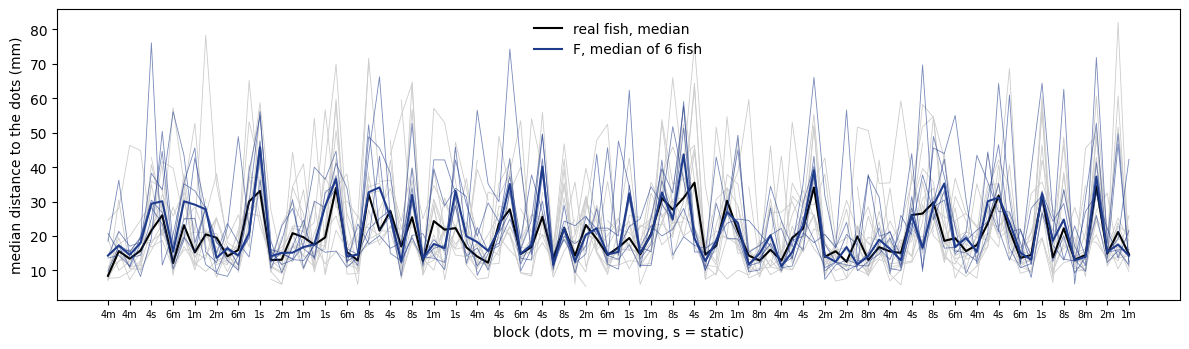

In [4]:
def per_block(block, x, y, cx, cy):
    d = pd.DataFrame(dict(block=block, dist=np.hypot(x - cx, y - cy) / PX_PER_MM)).dropna()
    return d[program.is_stim_of[d.block]].groupby("block").dist.median()


sim = pd.DataFrame({k: per_block(np.asarray(g["block_id"]), g["x_px"], g["y_px"], g["dot_cx"], g["dot_cy"])
                    for k, g in enumerate(rollouts)})
fig, ax = plt.subplots(figsize=(12, 3.6))
if program is rig and paths.BOUTS.exists():
    b = pd.read_csv(paths.BOUTS, usecols=["fish_id", "frame_onset", "x_px", "y_px", "dot_cx", "dot_cy"])
    b["block"] = program.block_id[np.clip(b.frame_onset, 0, program.n_frames - 1)]
    real = pd.DataFrame({f: per_block(d.block.to_numpy(), d.x_px, d.y_px, d.dot_cx, d.dot_cy)
                         for f, d in b.groupby("fish_id")})
    ax.plot(real.index, real, color="0.8", lw=0.6)
    ax.plot(real.index, real.median(axis=1), color="k", lw=1.5, label="real fish, median")
ax.plot(sim.index, sim, color=RV.SIM_COL, lw=0.6, alpha=0.6)
ax.plot(sim.index, sim.median(axis=1), color=RV.SIM_COL, lw=1.5, label=f"{MODEL}, median of {N_FISH} fish")
labels = [f"{int(program.n_dots_of[i])}{'m' if program.moving_of[i] else 's'}" for i in sim.index]
ax.set_xticks(sim.index[::max(1, len(sim) // 40)], labels[::max(1, len(sim) // 40)], fontsize=7)
ax.set(xlabel="block (dots, m = moving, s = static)", ylabel="median distance to the dots (mm)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

<a id="trajectories"></a>
## Trajectories

Each simulated fish over the whole programme.

[↑ back to contents](#contents)

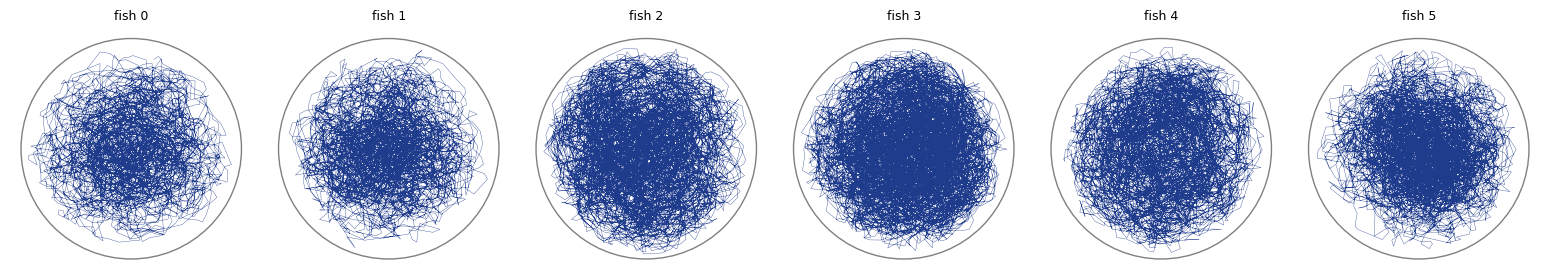

In [5]:
n = len(rollouts)
fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.8))
for ax, (k, g) in zip(np.atleast_1d(axes), enumerate(rollouts)):
    cx, cy, R = g["dish"]
    ax.add_patch(plt.Circle((cx, cy), R, fill=False, color="0.5"))
    ax.plot(g["x_px"], g["y_px"], lw=0.25, color=RV.SIM_COL)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off"); ax.set_title(f"fish {k}", fontsize=9)
plt.tight_layout(); plt.show()

<a id="check"></a>
## Against the real fish

The following index (probability of turning toward the dots, turns of more than 10°) by group size and the
distributions of the three emission heads (turn, distance, interval) and of the radial position, against a summary of
the real fish shipped in `assets/real_reference.npz`. On a programme of your own the real curves are those of the rig's
programme, so only a like-for-like condition compares.

[↑ back to contents](#contents)

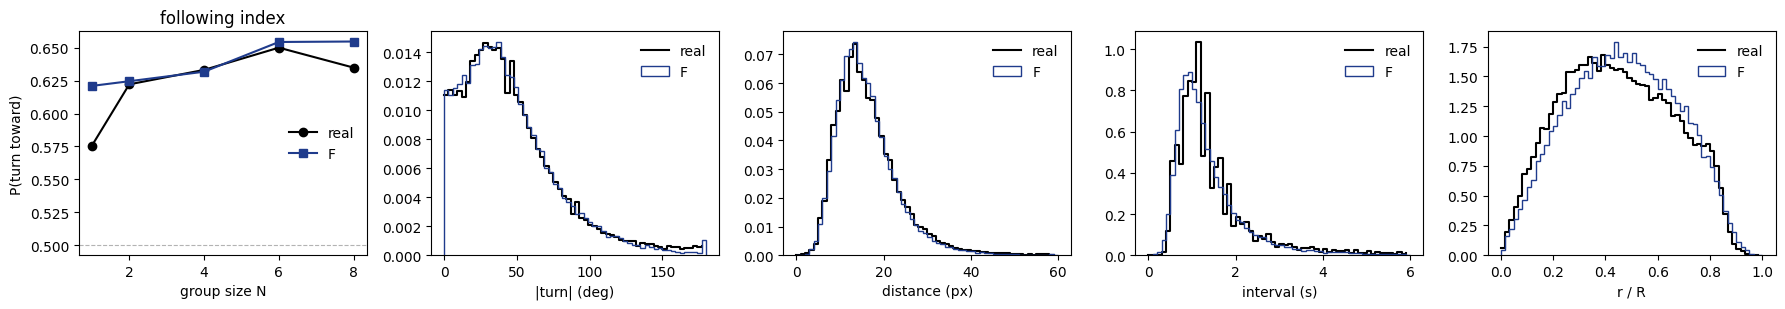

In [6]:
c = ref.curves
cat = lambda key: np.concatenate([np.asarray(g[key], float) for g in rollouts])          # noqa: E731
gen_n = np.concatenate([program.n_dots_of[g["block_id"]] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g["block_id"]].astype(float) for g in rollouts])
gen_rr = np.concatenate([np.hypot(g["x_px"] - g["dish"][0], g["y_px"] - g["dish"][1]) / g["dish"][2] for g in rollouts])
fi_real, fi_gen = c["following_by_n"], TR.following_by_n(cat("dtheta"), cat("stim_angle_gen"), gen_n, gen_mv)
panels = [("abs_dtheta", np.abs(cat("dtheta")), "|turn| (deg)"), ("dist", cat("distance_px"), "distance (px)"),
          ("dt", cat("dt_s"), "interval (s)"), ("rr", gen_rr, "r / R")]
fig, ax = plt.subplots(1, 5, figsize=(18, 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), "o-", color="k", label="real")
ax[0].plot(list(fi_gen), list(fi_gen.values()), "s-", color=RV.SIM_COL, label=MODEL)
ax[0].axhline(0.5, color="0.7", lw=0.8, ls="--")
ax[0].set(xlabel="group size N", ylabel="P(turn toward)", title="following index"); ax[0].legend(frameon=False)
for a, (k_, v, lab) in zip(ax[1:], panels):
    dens, e = c[k_]
    a.step(e[:-1], dens, where="post", color="k", label="real")
    a.hist(v[np.isfinite(v)], bins=len(dens), range=(e[0], e[-1]), density=True, histtype="step", color=RV.SIM_COL,
           label=MODEL)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

<a id="video"></a>
## Video

Two stimulus windows (rows; default: the first moving block at the largest group and the first static block at the
same size, `RV.pick_windows`; or set `WINDOWS = [(first frame, last frame, label), ...]`), three simulated fish and, on
the rig's programme, the real fish `REAL_FISH` in the same blocks, each with the dots it saw. Rendered once (about
2 min); delete the file to render it again.

[↑ back to contents](#contents)

In [7]:
WINDOWS = None
windows = WINDOWS or RV.pick_windows(program)
real = REAL_FISH if program is rig and paths.FRAMES.exists() else ()
mp4 = OUT / f"{Path(program.path).name.split('.csv')[0]}__{key}_seed{ROLL_SEED}.mp4"
if not mp4.exists():
    RV.write_video(rollouts, program, mp4, windows, n_sim=3, real_fish=real, speed=VIDEO_SPEED, model_label=MODEL)
for lo, hi, lab in windows:
    print(f"{lab}: frames {lo}-{hi}")
show(mp4, width=1100)

8 dots, moving (block 7): frames 11400-13200
8 dots, static (block 11): frames 18000-19800
